In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report


In [2]:
TRAIN_DIR = "Resources/1_Training"
VAL_DIR   = "Resources/2_Validation"
TEST_DIR  = "Resources/3_Testing"

IMG_SIZE = (128, 128)
BATCH_SIZE = 16   # SAFE for low-end PCs


In [3]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

val_gen = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)


Found 1154 images belonging to 2 classes.
Found 208 images belonging to 2 classes.
Found 200 images belonging to 2 classes.


In [4]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

base_model.trainable = False  # Stage 1

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.4)(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [5]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ModelCheckpoint("model/best_model.h5", save_best_only=True)
]


In [6]:
history = model.fit(
    train_gen,
    epochs=15,
    validation_data=val_gen,
    callbacks=callbacks
)


Epoch 1/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - accuracy: 0.8168 - loss: 0.3960

73/73 ━━━━━━━━━━━━━━━━━━━━ 32s 380ms/step - accuracy: 0.9038 - loss: 0.2242 - val_accuracy: 0.9808 - val_loss: 0.0739
Epoch 2/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.9753 - loss: 0.0720

73/73 ━━━━━━━━━━━━━━━━━━━━ 13s 177ms/step - accuracy: 0.9714 - loss: 0.0750 - val_accuracy: 0.9952 - val_loss: 0.0376
Epoch 3/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 14s 186ms/step - accuracy: 0.9792 - loss: 0.0554 - val_accuracy: 0.9712 - val_loss: 0.0805
Epoch 4/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 170ms/step - accuracy: 0.9792 - loss: 0.0566 - val_accuracy: 0.9808 - val_loss: 0.0598
Epoch 5/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.9880 - loss: 0.0424

73/73 ━━━━━━━━━━━━━━━━━━━━ 13s 179ms/step - accuracy: 0.9853 - loss: 0.0469 - val_accuracy: 0.9904 - val_loss: 0.0356
Epoch 6/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9830 - loss: 0.0492

73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 162ms/step - accuracy: 0.9835 - loss: 0.0455 - val_accuracy: 1.0000 - val_loss: 0.0170
Epoch 7/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 169ms/step - accuracy: 0.9896 - loss: 0.0352 - val_accuracy: 0.9904 - val_loss: 0.0276
Epoch 8/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.9896 - loss: 0.0317

73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 160ms/step - accuracy: 0.9870 - loss: 0.0393 - val_accuracy: 1.0000 - val_loss: 0.0143
Epoch 9/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.9866 - loss: 0.0479

73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 171ms/step - accuracy: 0.9844 - loss: 0.0423 - val_accuracy: 1.0000 - val_loss: 0.0116
Epoch 10/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 22s 184ms/step - accuracy: 0.9931 - loss: 0.0228 - val_accuracy: 1.0000 - val_loss: 0.0117
Epoch 11/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.9974 - loss: 0.0152

73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 170ms/step - accuracy: 0.9948 - loss: 0.0173 - val_accuracy: 1.0000 - val_loss: 0.0090
Epoch 12/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.9836 - loss: 0.0368

73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 168ms/step - accuracy: 0.9801 - loss: 0.0409 - val_accuracy: 0.9952 - val_loss: 0.0085
Epoch 13/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 11s 149ms/step - accuracy: 0.9861 - loss: 0.0383 - val_accuracy: 0.9856 - val_loss: 0.0292
Epoch 14/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 11s 146ms/step - accuracy: 0.9853 - loss: 0.0424 - val_accuracy: 0.9904 - val_loss: 0.0302
Epoch 15/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.9872 - loss: 0.0387

73/73 ━━━━━━━━━━━━━━━━━━━━ 11s 145ms/step - accuracy: 0.9861 - loss: 0.0366 - val_accuracy: 1.0000 - val_loss: 0.0080


In [7]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_finetune = model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    callbacks=callbacks
)


Epoch 1/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 22s 198ms/step - accuracy: 0.9411 - loss: 0.2289 - val_accuracy: 0.9615 - val_loss: 0.1263
Epoch 2/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 13s 173ms/step - accuracy: 0.9723 - loss: 0.0877 - val_accuracy: 0.9808 - val_loss: 0.0327
Epoch 3/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 161ms/step - accuracy: 0.9792 - loss: 0.0625 - val_accuracy: 0.9471 - val_loss: 0.1760
Epoch 4/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.9549 - loss: 0.1997

73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 166ms/step - accuracy: 0.9645 - loss: 0.1401 - val_accuracy: 1.0000 - val_loss: 0.0072
Epoch 5/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 161ms/step - accuracy: 0.9818 - loss: 0.0587 - val_accuracy: 0.9808 - val_loss: 0.0438
Epoch 6/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 164ms/step - accuracy: 0.9766 - loss: 0.0770 - val_accuracy: 0.9856 - val_loss: 0.0237
Epoch 7/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 165ms/step - accuracy: 0.9766 - loss: 0.0756 - val_accuracy: 0.9615 - val_loss: 0.0726
Epoch 8/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 160ms/step - accuracy: 0.9740 - loss: 0.0686 - val_accuracy: 0.9760 - val_loss: 0.0569
Epoch 9/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 12s 159ms/step - accuracy: 0.9818 - loss: 0.0515 - val_accuracy: 0.9663 - val_loss: 0.0972


In [8]:
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)

preds = model.predict(test_gen)
preds = (preds > 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(test_gen.classes, preds))

print("Classification Report:")
print(classification_report(test_gen.classes, preds))


13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 210ms/step - accuracy: 0.9650 - loss: 0.1277
Test Accuracy: 0.9649999737739563
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 159ms/step
Confusion Matrix:
[[94  6]
 [ 1 99]]
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.94      0.96       100
           1       0.94      0.99      0.97       100

    accuracy                           0.96       200
   macro avg       0.97      0.96      0.96       200
weighted avg       0.97      0.96      0.96       200



In [9]:
from tensorflow.keras.preprocessing import image

def predict_image(img_path):
    img = image.load_img(img_path, target_size=IMG_SIZE)
    img = image.img_to_array(img)
    img = preprocess_input(img)
    img = np.expand_dims(img, axis=0)

    pred = model.predict(img)[0][0]
    label = "Plastics" if pred > 0.5 else "Clean"

    print(f"Prediction: {label}")
    print(f"Confidence: {pred:.4f}")


In [14]:
predict_image(r"Resources/3_Testing/2_Microplastics/a--26-_jpg.rf.0ae749f9f22dbfa00f0889c68594bdc9.jpg")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Prediction: Plastics
Confidence: 1.0000


In [16]:
model.save("model/microplastics_model.keras")


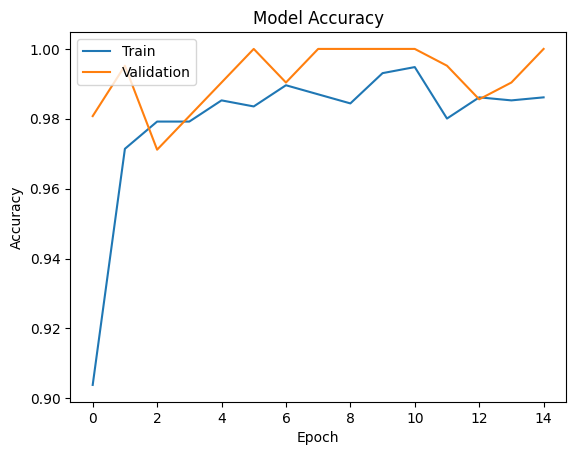

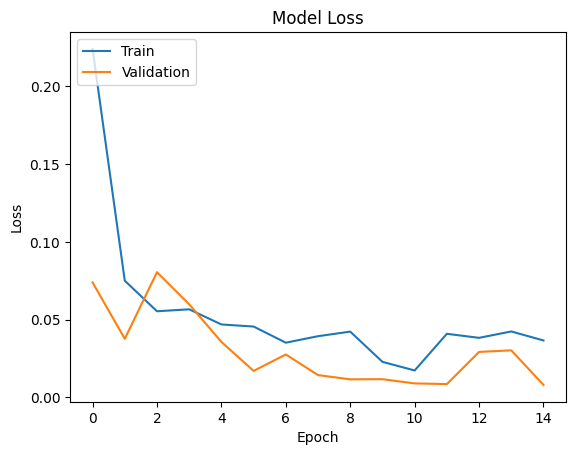

In [17]:
# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [20]:
# Testing alternative activation functions to find best candidates
from tensorflow.keras.models import Sequential
# Creating activation list
activation_functions = ['leaky_relu', 'elu', 'tanh', 'selu', 'sigmoid', 'relu']

# Creating a dictionary to hold the activation function accuracy results
results = {}

# For-Looping the activation functions through the model
for activation in activation_functions:
    print(f"Training model with activation: {activation}")

    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(64, activation=activation),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

    # Training the model
    history = model.fit(train_generator, epochs=15, validation_data=validation_generator)

    # Pulling the results
    results[activation] = history.history['val_accuracy']

# Plotting the results
plt.figure(figsize=(10, 6))

Training model with activation: leaky_relu


NameError: name 'train_generator' is not defined